In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [77]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [4]:
from sklearn.datasets import fetch_openml

# Load MNIST from OpenML.
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X = mnist.data.astype(np.float32).reshape(-1, 28, 28)
y = mnist.target.astype(np.int64)

# Keep only digits 0 and 8.
mask_08 = np.isin(y, [0, 8])
X_08 = X[mask_08]
y_08 = y[mask_08]

print("Full MNIST shape:", X.shape, y.shape)
print("Filtered 0/8 shape:", X_08.shape, y_08.shape)
print("Unique labels in filtered set:", np.unique(y_08))

Full MNIST shape: (70000, 28, 28) (70000,)
Filtered 0/8 shape: (13728, 28, 28) (13728,)
Unique labels in filtered set: [0 8]


In [6]:
# Binarize filtered images to pixels in {0, 1}.
threshold = 127.0
X_08_bin = (X_08 > threshold).astype(np.uint8)

print("Binarized shape:", X_08_bin.shape)
print("Unique pixel values:", np.unique(X_08_bin))

Binarized shape: (13728, 28, 28)
Unique pixel values: [0 1]


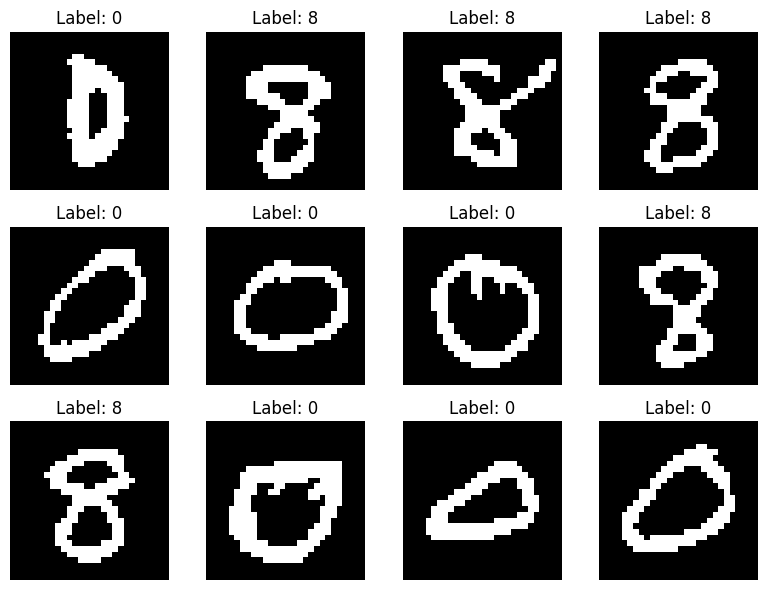

In [7]:
# Visualize random examples of digits 0 and 8.
rng = np.random.default_rng(42)
n_samples = 12
idx = rng.choice(len(X_08_bin), size=n_samples, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(8, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_08_bin[i], cmap="gray")
    ax.set_title(f"Label: {y_08[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# Pick a 0 by index (within the list of zeros), find the closest 8 by Hamming distance, and plot both.
zero_choice = 7  # Change this to choose a different 0 sample.

zero_indices = np.where(y_08 == 0)[0]
eight_indices = np.where(y_08 == 8)[0]

if not (0 <= zero_choice < len(zero_indices)):
    raise ValueError(f"zero_choice must be between 0 and {len(zero_indices) - 1}.")

selected_zero_idx = zero_indices[zero_choice]
zero_img = X_08_bin[selected_zero_idx]

eight_imgs = X_08_bin[eight_indices]
hamming_distances = np.count_nonzero(eight_imgs != zero_img, axis=(1, 2))
best_eight_pos = np.argmin(hamming_distances)
selected_eight_idx = eight_indices[best_eight_pos]
eight_img = X_08_bin[selected_eight_idx]

print(f"Selected 0 index in X_08_bin: {selected_zero_idx}")
print(f"Matched 8 index in X_08_bin: {selected_eight_idx}")
print(f"Hamming distance: {hamming_distances[best_eight_pos]}")

Selected 0 index in X_08_bin: 12
Matched 8 index in X_08_bin: 1037
Hamming distance: 107


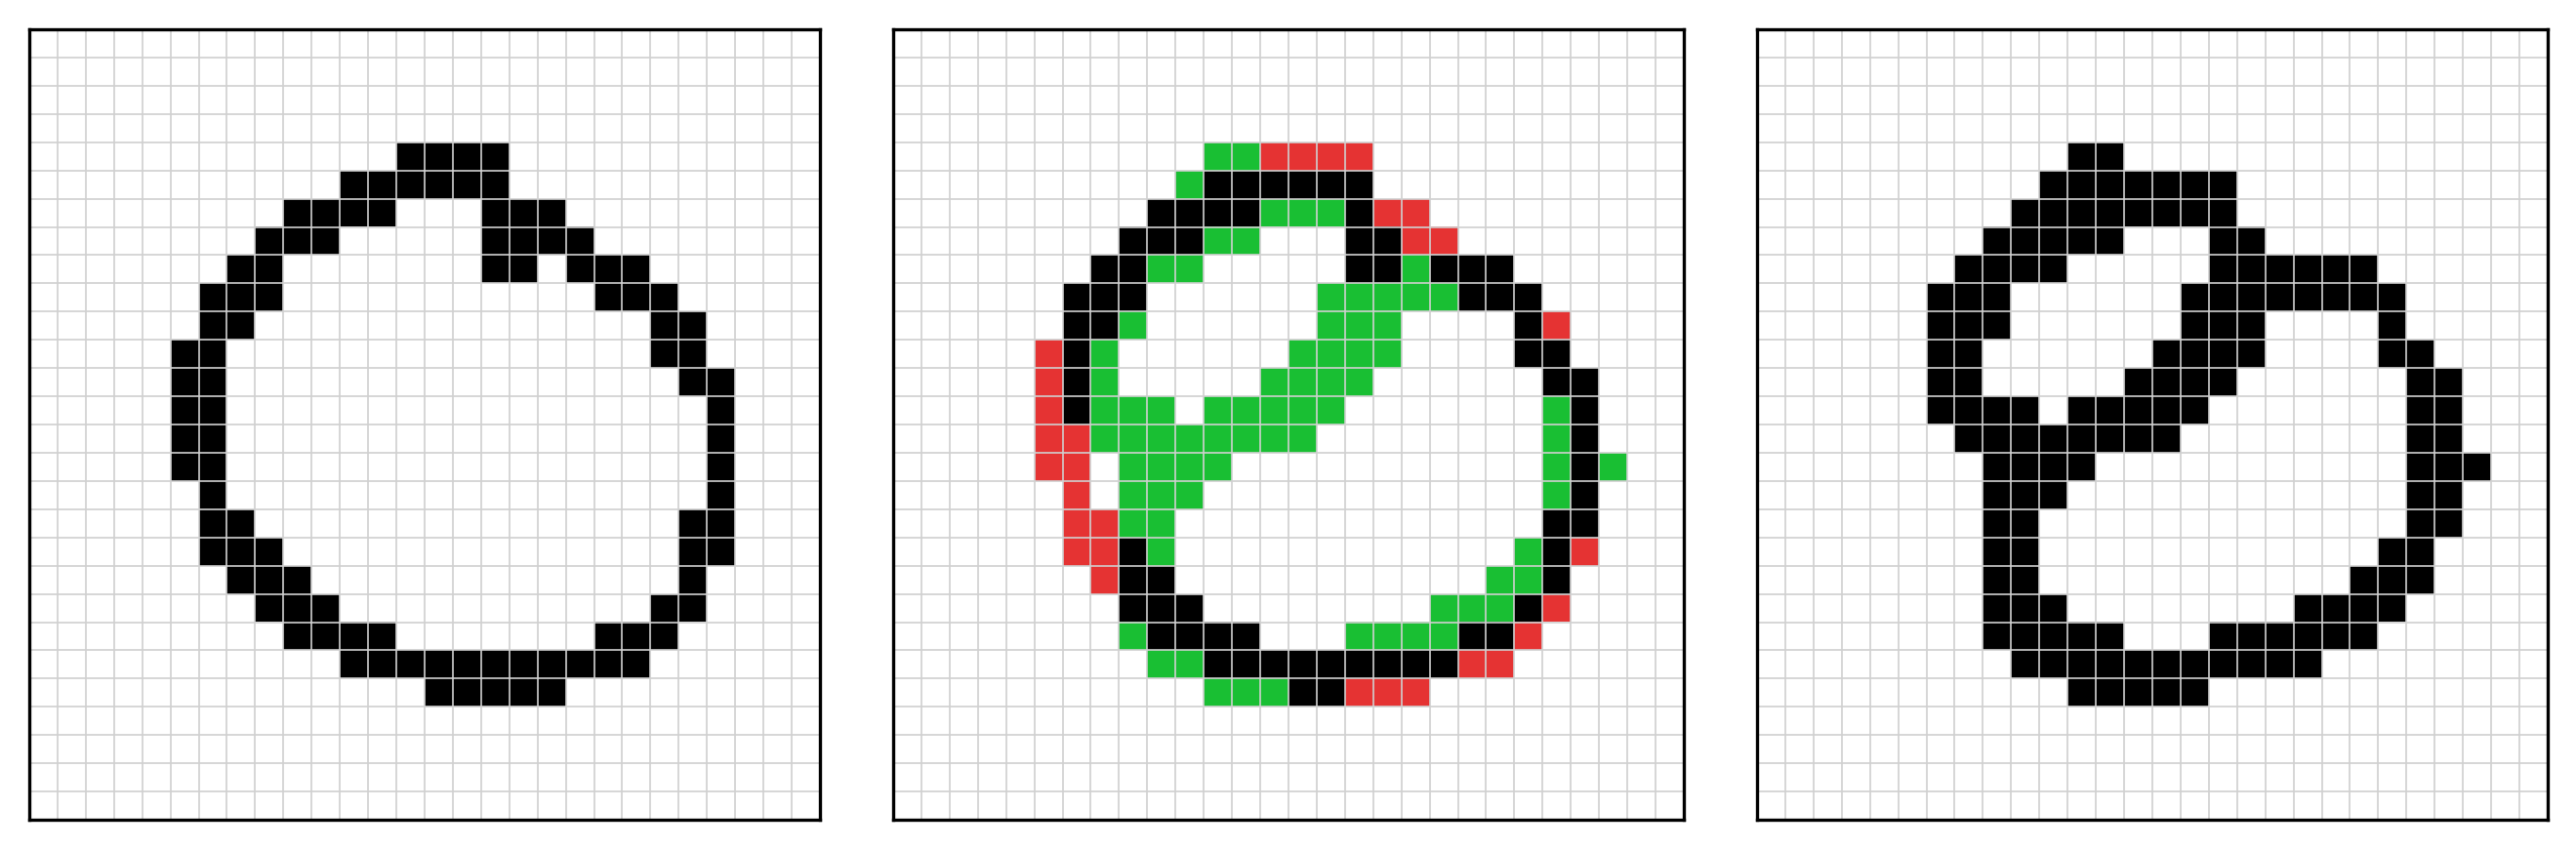

In [41]:
# Build an edit map to transform the selected 0 into the matched 8.
add_mask = (zero_img == 0) & (eight_img == 1)      # Add these pixels.
remove_mask = (zero_img == 1) & (eight_img == 0)   # Remove these pixels.
keep_mask = (zero_img == 1) & (eight_img == 1)     # Keep these 0-stroke pixels.

diff_rgb = np.ones((28, 28, 3), dtype=float)      # White background.
diff_rgb[keep_mask] = [0.0, 0.0, 0.0]              # Black = unchanged 0 pixels.
diff_rgb[add_mask] = [0.1, 0.75, 0.2]              # Green = add.
diff_rgb[remove_mask] = [0.9, 0.2, 0.2]            # Red = remove.

fig, axes = plt.subplots(1, 3, figsize=(9, 3), facecolor="white", dpi=300)
panels = [zero_img, diff_rgb, eight_img]
cmaps = ["gray_r", None, "gray_r"]

for ax, panel, cmap in zip(axes, panels, cmaps):
    if cmap is None:
        ax.imshow(panel, interpolation="nearest")
    else:
        ax.imshow(panel, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")

    ax.set_facecolor("white")
    ax.set_xticks(np.arange(-0.5, 28, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 28, 1), minor=True)
    ax.grid(which="minor", color="#d0d0d0", linestyle="-", linewidth=0.4)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.savefig("../results/Images/MNIST/mnist_0_to_8_edit.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Flatten 28x28 binary images into feature vectors.
X_lr = X_08_bin.reshape(len(X_08_bin), -1)
y_lr = y_08

# Keep a fixed test split for evaluation.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_lr,
    y_lr,
    test_size=0.2,
    random_state=42,
    stratify=y_lr,
 )

# Train on only 1000 samples to make the classifier weaker.
num_usable_samples = 10900
n_train_small = min(num_usable_samples, len(X_train_full))
X_train, _, y_train, _ = train_test_split(
    X_train_full,
    y_train_full,
    train_size=n_train_small,
    random_state=42,
    stratify=y_train_full,
 )

clf = LogisticRegression(max_iter=2000, solver="lbfgs")
clf.fit(X_train, y_train)

y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 8])

print(f"Training samples used: {len(X_train)}")
print(f"Train accuracy: {train_acc:.4f}")
print(f"Test accuracy:  {test_acc:.4f}")
print("Confusion matrix (rows=true [0,8], cols=pred [0,8]):")
print(cm)

Training samples used: 10900
Train accuracy: 0.9978
Test accuracy:  0.9924
Confusion matrix (rows=true [0,8], cols=pred [0,8]):
[[1370   11]
 [  10 1355]]


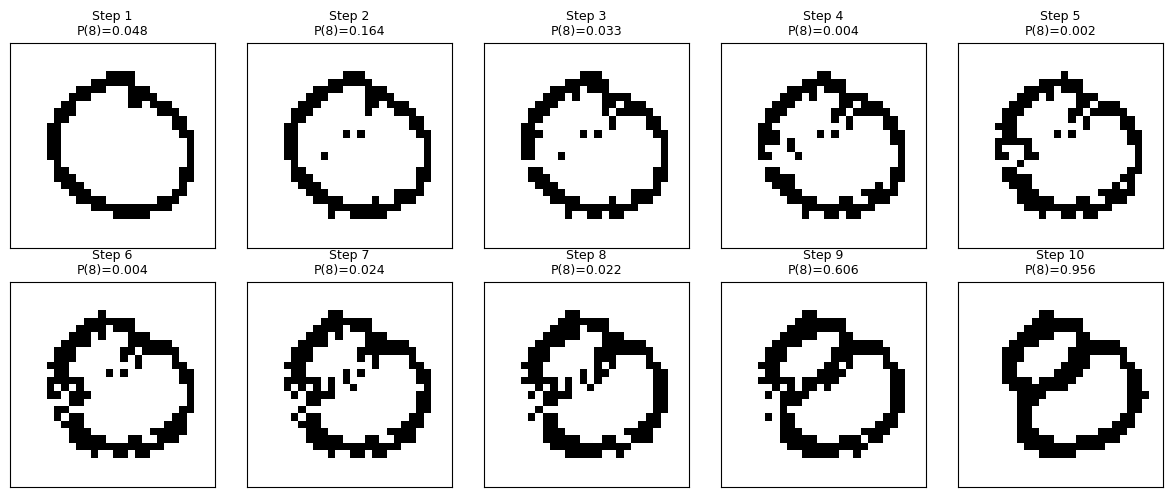

Step | Changed pixels | P(class=8)
   1 |              0 | 0.0479
   2 |             11 | 0.1637
   3 |             23 | 0.0331
   4 |             35 | 0.0043
   5 |             47 | 0.0023
   6 |             59 | 0.0040
   7 |             71 | 0.0238
   8 |             83 | 0.0218
   9 |             95 | 0.6064
  10 |            107 | 0.9556


In [43]:
# Create 10 progressive mutations from the selected 0 toward the matched 8, then score P(class=8).
n_steps = 10
start_img = zero_img.copy()
target_img = eight_img.copy()

# Pixels that differ between source 0 and target 8.
diff_coords = np.argwhere(start_img != target_img)
n_changes = len(diff_coords)

# Fixed order so the interpolation is reproducible.
rng_interp = np.random.default_rng(0)
diff_coords = diff_coords[rng_interp.permutation(n_changes)]

# Number of applied pixel changes at each step (includes start and end).
changes_per_step = np.linspace(0, n_changes, n_steps, dtype=int)

interp_images = []
p8_values = []
class8_col = np.where(clf.classes_ == 8)[0][0]

for n_apply in changes_per_step:
    img = start_img.copy()
    if n_apply > 0:
        coords = diff_coords[:n_apply]
        rr, cc = coords[:, 0], coords[:, 1]
        img[rr, cc] = target_img[rr, cc]

    interp_images.append(img)
    p8 = clf.predict_proba(img.reshape(1, -1))[0, class8_col]
    p8_values.append(p8)

# Visualize the 10-step path.
fig, axes = plt.subplots(2, 5, figsize=(12, 5), facecolor="white")
for step, (ax, img, p8) in enumerate(zip(axes.ravel(), interp_images, p8_values), start=1):
    ax.imshow(img, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"Step {step}\nP(8)={p8:.3f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print("Step | Changed pixels | P(class=8)")
for step, (n_apply, p8) in enumerate(zip(changes_per_step, p8_values), start=1):
    print(f"{step:>4} | {n_apply:>14} | {p8:.4f}")

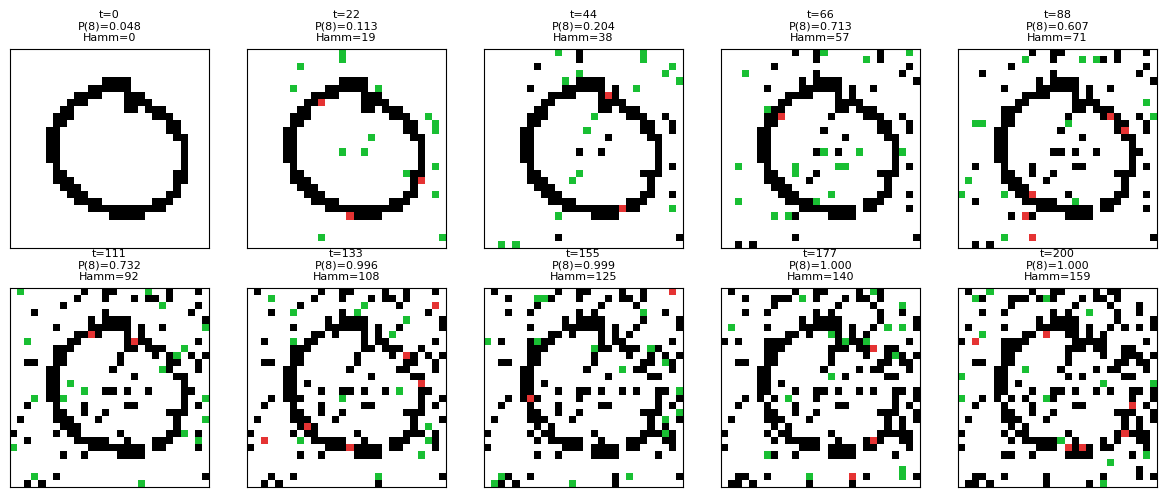

beta=1.0, lambda_=10.0
Accepted moves: 181/200 (0.905)
Initial P(8): 0.0479 | Initial Hamming: 0 (0.000)
Final   P(8): 1.0000 | Final   Hamming: 159 (0.203)


In [75]:
# Metropolis Monte Carlo with a two-term Hamiltonian:
# H(x) = -beta * logit_8(x) + lambda_ * hamming_frac(x, zero_img)
n_mc_steps = 200
beta = 1.0      # Weight for classifier logit term.
lambda_ = 10.0  # Weight for Hamming-distance penalty (increase to reduce noise).
rng_mc = np.random.default_rng(4)

# In this notebook clf.classes_ = [0, 8], so decision_function is the logit for class 8 vs 0.
def logit_8(img):
    return float(clf.decision_function(img.reshape(1, -1))[0])

def hamming_to_zero(img):
    return int(np.count_nonzero(img != zero_img))

def hamming_frac_to_zero(img):
    return hamming_to_zero(img) / img.size

def hamiltonian(img):
    beta_term = -beta * logit_8(img)
    lambda_term = lambda_ * hamming_frac_to_zero(img)
    return beta_term, lambda_term, beta_term + lambda_term

def render_with_delta(curr_img, prev_img=None):
    # Base image: black strokes on white background.
    rgb = np.ones((28, 28, 3), dtype=float)
    rgb[curr_img == 1] = [0.0, 0.0, 0.0]

    if prev_img is not None:
        add_mask = (prev_img == 0) & (curr_img == 1)
        remove_mask = (prev_img == 1) & (curr_img == 0)
        rgb[add_mask] = [0.1, 0.75, 0.2]   # Green = added pixels.
        rgb[remove_mask] = [0.9, 0.2, 0.2] # Red = removed pixels.

    return rgb

current_img = zero_img.copy().astype(np.uint8)
beta_term, lambda_term, current_H = hamiltonian(current_img)

snapshot_steps = np.linspace(0, n_mc_steps, 10, dtype=int)
snapshot_set = set(snapshot_steps.tolist())
snapshots = {}

accepted_moves = 0
for step in range(n_mc_steps + 1):
    if step in snapshot_set:
        p8 = float(clf.predict_proba(current_img.reshape(1, -1))[0, np.where(clf.classes_ == 8)[0][0]])
        ham = hamming_to_zero(current_img)
        ham_frac = hamming_frac_to_zero(current_img)
        snapshots[step] = (current_img.copy(), p8, ham, ham_frac, current_H)

    if step == n_mc_steps:
        break

    # Propose a one-pixel flip.
    r = rng_mc.integers(0, 28)
    c = rng_mc.integers(0, 28)
    proposal_img = current_img.copy()
    proposal_img[r, c] = 1 - proposal_img[r, c]

    beta_term, lambda_term, proposal_H = hamiltonian(proposal_img)
    delta_H = proposal_H - current_H

    # Metropolis rule on Hamiltonian: accept always if H decreases,
    # otherwise accept with probability exp(-delta_H).
    if delta_H <= 0:
        accept = True
    else:
        accept_prob = np.exp(-delta_H)
        accept = rng_mc.random() < accept_prob

    if accept:
        current_img = proposal_img
        current_H = proposal_H
        accepted_moves += 1

# Display 10 equally spaced snapshots with delta coloring vs previous snapshot.
fig, axes = plt.subplots(2, 5, figsize=(12, 5), facecolor="white")
prev_img = None
for ax, step in zip(axes.ravel(), snapshot_steps):
    img, p8, ham, ham_frac, H = snapshots[int(step)]
    img_rgb = render_with_delta(img, prev_img)
    ax.imshow(img_rgb, interpolation="nearest")
    ax.set_title(f"t={int(step)}\nP(8)={p8:.3f}\nHamm={ham}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    prev_img = img

plt.tight_layout()
plt.show()

acceptance_rate = accepted_moves / n_mc_steps
start_step = int(snapshot_steps[0])
end_step = int(snapshot_steps[-1])

print(f"beta={beta}, lambda_={lambda_}")
print(f"Accepted moves: {accepted_moves}/{n_mc_steps} ({acceptance_rate:.3f})")
print(
    f"Initial P(8): {snapshots[start_step][1]:.4f} | "
    f"Initial Hamming: {snapshots[start_step][2]} ({snapshots[start_step][3]:.3f})"
 )
print(
    f"Final   P(8): {snapshots[end_step][1]:.4f} | "
    f"Final   Hamming: {snapshots[end_step][2]} ({snapshots[end_step][3]:.3f})"
 )

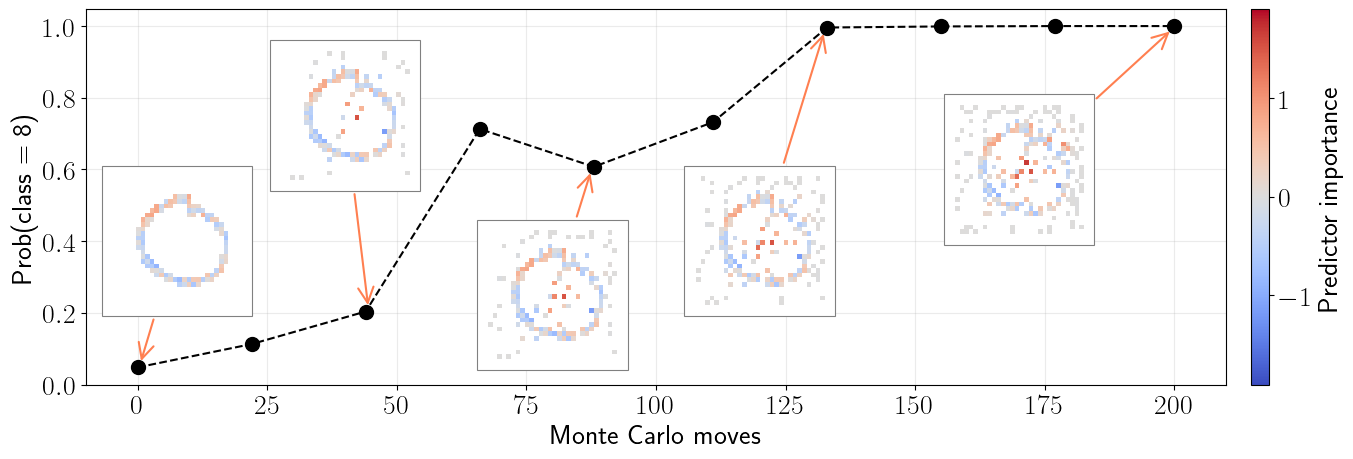

In [144]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib import colors
from matplotlib.cm import ScalarMappable

plt.rcParams.update({"font.size": 20})

# Build x/y arrays from stored MC snapshots.
x_steps = np.array(sorted(snapshots.keys()))
y_probs = np.array([snapshots[s][1] for s in x_steps])
snapshot_imgs = [snapshots[s][0] for s in x_steps]

# Choose how many thumbnails to show (always includes first and last).
n_display = 5
if not (2 <= n_display <= len(x_steps)):
    raise ValueError(f"n_display must be between 2 and {len(x_steps)}")

selected_pos = np.unique(np.linspace(0, len(x_steps) - 1, n_display, dtype=int))
sel_x = x_steps[selected_pos]
sel_y = y_probs[selected_pos]
sel_imgs = [snapshot_imgs[i] for i in selected_pos]

fig, ax = plt.subplots(figsize=(14, 5), facecolor="white")
ax.plot(x_steps, y_probs, "--o", color="black", lw=1.5, ms=10)
ax.set_xlabel("Monte Carlo moves")
ax.set_ylabel("Prob(class = 8)")
ax.set_yticks(np.linspace(0.0, 1.0, 6))
ax.grid(alpha=0.25)

# Use current axis limits (do not override them).
xmin_plot, xmax_plot = ax.get_xlim()
ymin_plot, ymax_plot = ax.get_ylim()
x_span = xmax_plot - xmin_plot
y_span = ymax_plot - ymin_plot

# Predictor importance map from logistic regression coefficients.
importance_map = clf.coef_.reshape(28, 28)
vmax = np.max(np.abs(importance_map))
norm = colors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
cmap_imp = plt.get_cmap("coolwarm")
alpha_importance = 1.0  # Slightly stronger color opacity on active pixels.

# Add side colorbar for importance values.
sm = ScalarMappable(norm=norm, cmap=cmap_imp)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.045, pad=0.02)
cbar.set_label("Predictor importance")

# Manual x coordinates for image centers (one value per displayed image).
# Edit these values to move images left/right.
x_image_coords = [
    1, 40, 80, 120, 170
 ]

# Manual y coordinates for image centers (one value per displayed image).
# Edit these values to move images up/down.
y_image_coords = [
    0.4, 0.75, 0.25, 0.4, 0.6
 ]

if len(x_image_coords) != len(sel_x):
    raise ValueError(f"x_image_coords must have length {len(sel_x)}")
if len(y_image_coords) != len(sel_x):
    raise ValueError(f"y_image_coords must have length {len(sel_x)}")

for i, (x, y, img) in enumerate(zip(sel_x, sel_y, sel_imgs)):
    # White background; active pixels are colored by predictor importance.
    img_rgb = np.ones((28, 28, 3), dtype=float)
    active_mask = img == 1
    if np.any(active_mask):
        base_colors = cmap_imp(norm(importance_map[active_mask]))[:, :3]
        img_rgb[active_mask] = (1 - alpha_importance) * np.ones(3) + alpha_importance * base_colors

    x_img = float(np.clip(x_image_coords[i], xmin_plot + 0.08 * x_span, xmax_plot - 0.08 * x_span))
    y_img = float(np.clip(y_image_coords[i], ymin_plot + 0.05 * y_span, ymax_plot - 0.05 * y_span))

    shift_x = 0.5
    shift_y = 0.01
    x_arrow = x + shift_x if i <= 1 else x - shift_x
    y_arrow = y + shift_y if i <= 1 else y - shift_y
    ab = AnnotationBbox(
        OffsetImage(img_rgb, zoom=3.3, interpolation="nearest"),
        (x_arrow, y_arrow),
        xybox=(x_img, y_img),
        xycoords="data",
        boxcoords="data",
        frameon=True,
        bboxprops=dict(edgecolor="0.5", linewidth=0.8, facecolor="white"),
        arrowprops=dict(arrowstyle="->", color="coral", lw=1.5),
    )
    ax.add_artist(ab)

plt.tight_layout()
plt.savefig("../results/Images/MNIST/mnist_mc_trajectory.png", dpi=300)
plt.savefig("../results/Images/MNIST/mnist_mc_trajectory.pdf", dpi=300, bbox_inches="tight")
plt.show()

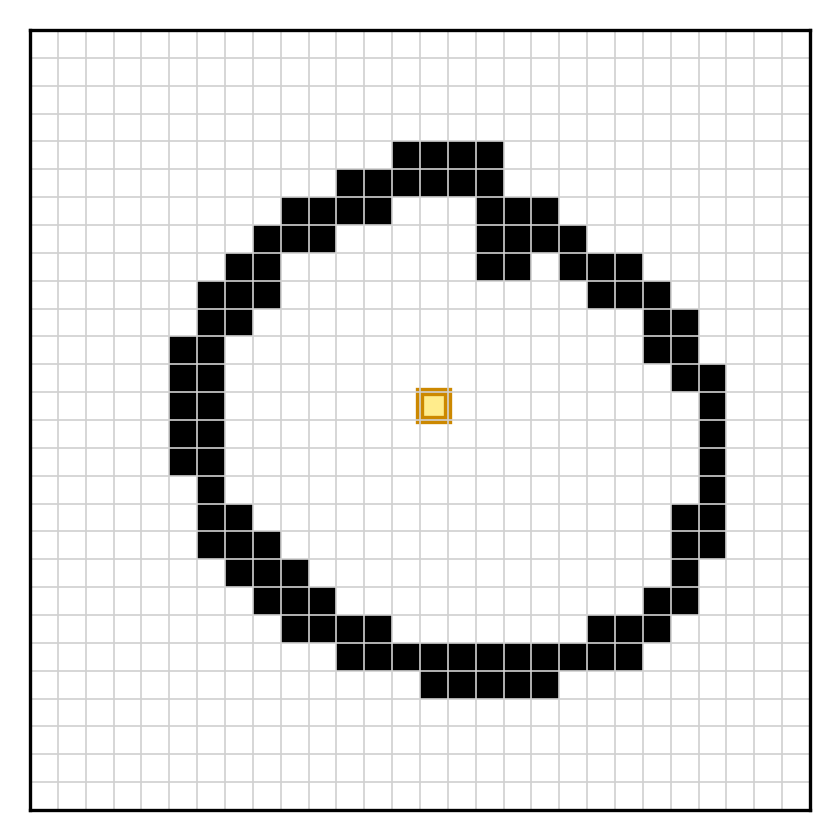

Proposed mutation pixel: row=13, col=14
Pixel value: 0 -> 1
P8 before: 0.047870 | P8 after: 0.178469
log(P8_after / P8_before): 1.315922
decision_function before: -2.990209 | after: -1.526755
Delta logit (decision_function, after - before): 1.463453
Delta beta term = -beta * Delta logit: -1.463453


In [152]:
from matplotlib.patches import Rectangle

# Single-image view (like the left panel style): starting 0 + one proposed mutation pixel.
# Set row/col manually, or keep None to sample one random pixel.
proposed_row = 13
proposed_col = 14

if proposed_row is None or proposed_col is None:
    rng_prop = np.random.default_rng(123)
    proposed_row = int(rng_prop.integers(0, 28))
    proposed_col = int(rng_prop.integers(0, 28))

if not (0 <= proposed_row < 28 and 0 <= proposed_col < 28):
    raise ValueError("proposed_row and proposed_col must be in [0, 27].")

pixel_before = int(zero_img[proposed_row, proposed_col])
pixel_after = 1 - pixel_before

# Build mutated image with the proposed one-pixel flip.
mut_img = zero_img.copy()
mut_img[proposed_row, proposed_col] = pixel_after

# Class probabilities before/after mutation.
p_orig = clf.predict_proba(zero_img.reshape(1, -1))[0]
p_mut = clf.predict_proba(mut_img.reshape(1, -1))[0]
p0_orig, p8_orig = float(p_orig[0]), float(p_orig[1])
p0_mut, p8_mut = float(p_mut[0]), float(p_mut[1])

# Log probability ratio for class 8.
eps = 1e-12
log_prob_ratio_8 = np.log((p8_mut + eps) / (p8_orig + eps))

# Delta logit from logistic-regression decision function.
logit_orig = float(clf.decision_function(zero_img.reshape(1, -1))[0])
logit_mut = float(clf.decision_function(mut_img.reshape(1, -1))[0])
delta_logit = logit_mut - logit_orig

# This matches the Metropolis beta-term change used in the simulation.
delta_beta_term = -beta * delta_logit

fig, ax = plt.subplots(1, 1, figsize=(3.2, 3.2), facecolor="white", dpi=300)
ax.imshow(zero_img, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
ax.set_facecolor("white")

# Pixel grid.
ax.set_xticks(np.arange(-0.5, 28, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 28, 1), minor=True)
ax.grid(which="minor", color="#d0d0d0", linestyle="-", linewidth=0.4)

# Highlight proposed mutation pixel.
highlight = Rectangle(
    (proposed_col - 0.5, proposed_row - 0.5),
    1,
    1,
    facecolor=(1.0, 0.84, 0.0, 0.45),
    edgecolor="#cc8800",
    linewidth=2.0,
 )
ax.add_patch(highlight)

ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.show()

print(f"Proposed mutation pixel: row={proposed_row}, col={proposed_col}")
print(f"Pixel value: {pixel_before} -> {pixel_after}")
print(f"P8 before: {p8_orig:.6f} | P8 after: {p8_mut:.6f}")
print(f"log(P8_after / P8_before): {log_prob_ratio_8:.6f}")
print(f"decision_function before: {logit_orig:.6f} | after: {logit_mut:.6f}")
print(f"Delta logit (decision_function, after - before): {delta_logit:.6f}")
print(f"Delta beta term = -beta * Delta logit: {delta_beta_term:.6f}")

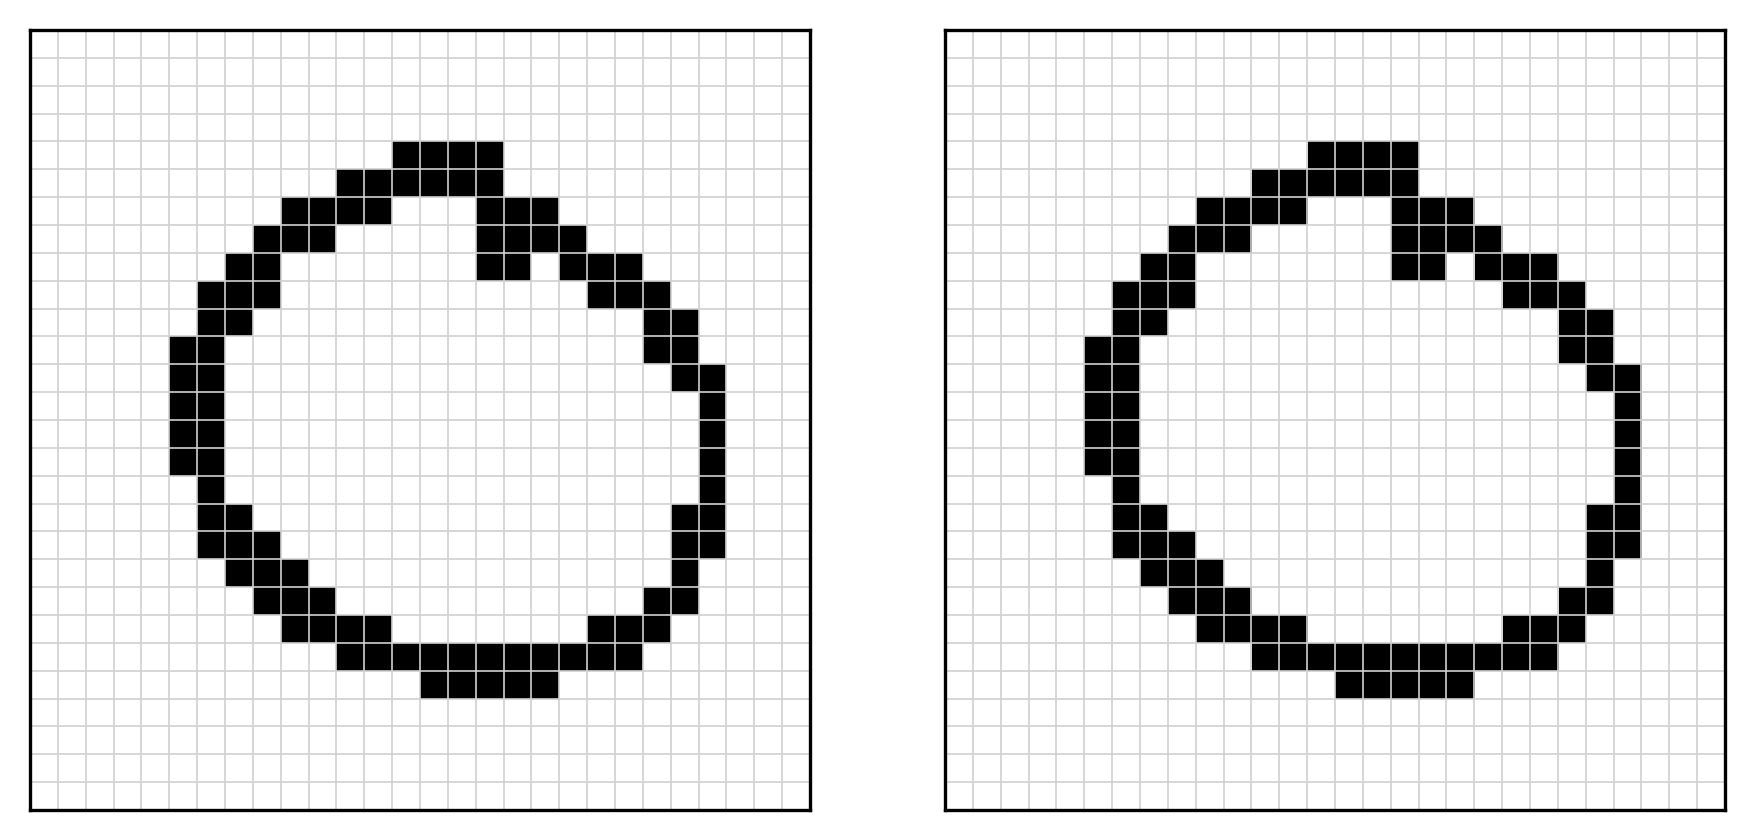

Selected pixel highlighted in both panels: row=13, col=14


In [156]:
from matplotlib.patches import Rectangle

# Two-panel view: same selected pixel in green (left) and red (right).
# If not already defined, pick a random proposed pixel.
if "proposed_row" not in globals() or "proposed_col" not in globals():
    rng_prop = np.random.default_rng(123)
    proposed_row = int(rng_prop.integers(0, 28))
    proposed_col = int(rng_prop.integers(0, 28))

fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2), facecolor="white", dpi=300)
highlight_colors = [((0.1, 0.75, 0.2, 0.45), "#2e7d32"), ((0.9, 0.2, 0.2, 0.45), "#b71c1c")]

for ax, (face_col, edge_col) in zip(axes, highlight_colors):
    ax.imshow(zero_img, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_facecolor("white")
    ax.set_xticks(np.arange(-0.5, 28, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 28, 1), minor=True)
    ax.grid(which="minor", color="#d0d0d0", linestyle="-", linewidth=0.4)

    # rect = Rectangle(
    #     (proposed_col - 0.5, proposed_row - 0.5),
    #     1,
    #     1,
    #     facecolor=face_col,
    #     edgecolor=edge_col,
    #     linewidth=2.0,
    # )
    # ax.add_patch(rect)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.show()

print(f"Selected pixel highlighted in both panels: row={proposed_row}, col={proposed_col}")